Categorical Boosting

In [1]:
!pip install catboost
!pip install pandas
!pip install seaborn
!pip install matplotlib



[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from catboost import CatBoostClassifier

In [3]:
# Load the Titanic dataset
titanic = sns.load_dataset('titanic')
target = 'survived'

In [4]:
# preprocessing data

# filling missing value in deck column with a new category: Unknown
categories = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'Unknown']
titanic['deck'] = pd.Categorical(
    titanic['deck'], categories=categories, ordered=True)
titanic['deck'] = titanic['deck'].fillna('Unknown')

# filling missing value in age column using mean imputation
age_mean = titanic['age'].fillna(0).mean()
titanic['age'] = titanic['age'].fillna(age_mean)

# droping missing values in embark as there are only 2
titanic = titanic.dropna()

# droping alive column to make the problem more challenging
titanic = titanic.drop('alive', axis=1)

In [5]:
# Creating CatBoost Pool object
# Create the feature matrix (X) and target vector (y)
X = titanic.drop(target, axis=1)
y = titanic[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
# Model Training
# specifying categorical features
categorical_features = ['sex', 'pclass', 'sibsp', 'parch', 'embarked',
                        'class', 'who', 'adult_male', 'embark_town', 'alone', 'deck']
# create and train the CatBoostClassifier
model = CatBoostClassifier(iterations=100, depth=8, learning_rate=0.1, cat_features=categorical_features,
                           loss_function='Logloss', custom_metric=['AUC'], random_seed=42)
model.fit(X_train, y_train)

0:	learn: 0.6571312	total: 198ms	remaining: 19.6s
1:	learn: 0.6221910	total: 275ms	remaining: 13.4s
2:	learn: 0.5939753	total: 325ms	remaining: 10.5s
3:	learn: 0.5702463	total: 396ms	remaining: 9.5s
4:	learn: 0.5494485	total: 428ms	remaining: 8.14s
5:	learn: 0.5318808	total: 493ms	remaining: 7.72s
6:	learn: 0.5166735	total: 559ms	remaining: 7.42s
7:	learn: 0.5034372	total: 609ms	remaining: 7s
8:	learn: 0.4912526	total: 683ms	remaining: 6.9s
9:	learn: 0.4836415	total: 712ms	remaining: 6.41s
10:	learn: 0.4743785	total: 801ms	remaining: 6.48s
11:	learn: 0.4658533	total: 875ms	remaining: 6.42s
12:	learn: 0.4581934	total: 895ms	remaining: 5.99s
13:	learn: 0.4502682	total: 936ms	remaining: 5.75s
14:	learn: 0.4447627	total: 956ms	remaining: 5.42s
15:	learn: 0.4418242	total: 970ms	remaining: 5.09s
16:	learn: 0.4361839	total: 1.03s	remaining: 5.03s
17:	learn: 0.4321366	total: 1.11s	remaining: 5.05s
18:	learn: 0.4272143	total: 1.18s	remaining: 5.04s
19:	learn: 0.4222480	total: 1.29s	remaining: 5

In [7]:
# Make predictions and Evaluate the Model
# predicting accuracy
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

# print accuracy
print(f"Accuracy: {accuracy:.2f}")

Accuracy: 0.80


In [8]:
# Plot the confusion matrix as a heatmap
# plt.figure(figsize=(8, 6))
# sns.heatmap(confusion, annot=True, fmt='d', cmap='Blues', xticklabels=[
#             'Predicted Negative', 'Predicted Positive'], yticklabels=['Actual Negative', 'Actual Positive'])
# plt.xlabel('Predicted')
# plt.ylabel('Actual')
# plt.title('Confusion Matrix')
# plt.show()

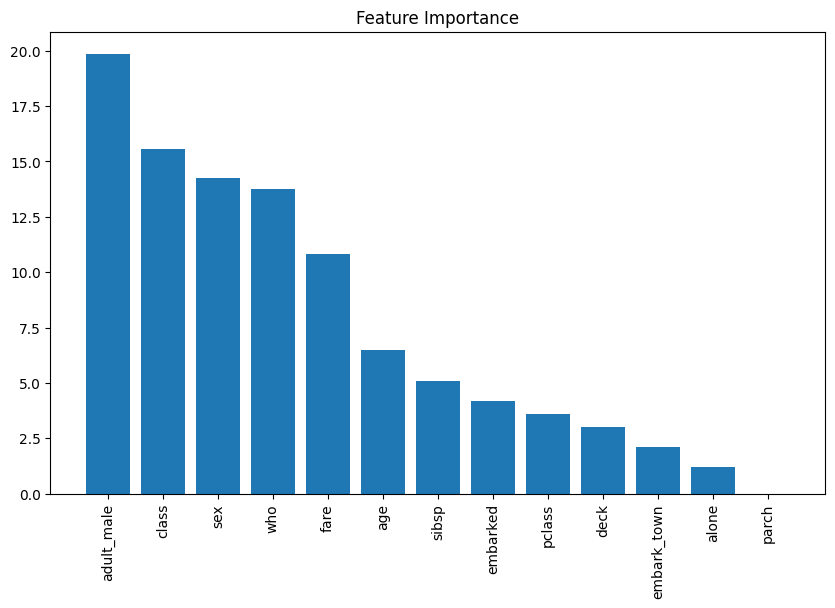

In [9]:
importances = model.get_feature_importance()
feature_names = X.columns
sorted_indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 6))
plt.bar(range(len(feature_names)), importances[sorted_indices])
plt.xticks(range(len(feature_names)), feature_names[sorted_indices], rotation=90)
plt.title("Feature Importance")
plt.show()

In [10]:
# Print the classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.87      0.84       109
           1       0.77      0.70      0.73        69

    accuracy                           0.80       178
   macro avg       0.80      0.78      0.79       178
weighted avg       0.80      0.80      0.80       178

